---
layout: article
title: Competitiveness of an environment
custom_css: article.css
include_mathjax: true
---

In [1]:
# import necessary libs (available in jupyter/scipy-notebook docker image)
import os
import pandas as pd 
import numpy as np
import math
import matplotlib.pyplot as plt 
from matplotlib.ticker import FormatStrFormatter

# define watermark 
def add_watermark(ax, x, y):
    ax.text(ax.get_xlim()[0]+ x,
            ax.get_ylim()[0]+ y,
            "ladydragoncapital",
            alpha=0.3, fontsize=16)


# globals
HOME_DIR = '/home/jovyan/_jupyter'
DATA_DIR = os.path.join(HOME_DIR, 'data')

# read in csv data
cities = pd.read_csv(os.path.join(DATA_DIR, 'Heilongjiang_city_data_07052026.csv'))
districts = pd.read_csv(os.path.join(DATA_DIR, 'Hegang_Daxinganling_district_data_07052026.csv'))
df = cities[11:14]
df= df.round(decimals=2)

## 1. Introduction ##

Choosing the right environment for a home or business requires more than intuition; it demands a systematic method to evaluate whether a location will improve our long-term position. In this article, we develop a macro-level framework for analyzing cities. By understanding the big picture, we can accurately gauge a region's competitiveness and anticipate how those broader forces will shape its housing market.

## 2. Macro vs. Micro Analysis ##

Evaluating a region effectively requires looking at it through two distinct lenses: macro and micro.

Macro analysis acts as a diagnostic checkup for an entire region. It assesses overall health, identifies major trends, and highlights systemic risks and opportunities. Crucially, it reveals the big-picture forces that affect everyone in that area, regardless of their specific industry or asset.

Micro analysis, by contrast, is a deep dive into the small-scale details of a particular asset, business, or neighborhood.

A helpful analogy is that macro analysis is a telescope, used to "zoom out" and identify regions with undervalued potential. Micro analysis is a microscope, used to "zoom in" and inspect individual assets (e.g., roof condition, plumbing, price per square foot, local traffic) to find the single best investment within that region.
Macro analysis must always provide the context for micro decisions. For example, if your macro analysis reveals a region with a declining population, you would know it is inherently risky to open a new school there. The micro decision is directly informed by the macro picture.

A comprehensive macro analysis typically covers six key areas, also known as PESTEL:

+ Political
+ Economic
+ Social/Demographic
+ Technological
+ Environmental/Climate
+ Legal

Since in this article we will compare cities within the same province, they share the same political systems, legal frameworks, climatic conditions, and technological infrastructure, these factors are treated as constants and excluded from this comparative analysis. Therefore, the key differentiators for property investment viability are reduced to two core pillars: **Economic Vitality** and **Demographic Momentum**.

To build this framework, we use GDP per capita as the primary indicator of economic vitality. For demographic momentum, we analyze population density and the natural growth rate. 


## 3. Analytical Framework: Interpreting the Three Indicators ##

3.1 What each indicator tells you?

When combined, GDP per capita, population density, and population natural growth rate, you get a powerful, multi-dimensional snapshot of a place. No single number tells the whole story, but together, they reveal a region's wealth, livability, development stage, and future challenges.

What Each Metric Tells You Individually:

+ GDP per capita: This measures average wealth and productivity. It serves as a proxy for the local standard of living, prevailing wage levels, and the overall sophistication of the economy (e.g., distinguishing a high-tech hub from an agriculture-based region).
  
+ Population Density: This tracks the number of people (residents and tourists) per square kilometer. It reflects current market pressure and the degree to which an area is built up versus rural. High density signals intense competition for finite resources, including housing, infrastructure, and public services.
  
+ Population Natural Growth Rate: Calculated as births minus deaths (per 1,000 people), this metric isolates demographic momentum by excluding migration. A positive rate suggests a young, organically growing population, while a negative rate warns of an aging, shrinking local base.

3.2 Archetypes: What the Combinations Reveal

The intersection of these three variables creates distinct regional profiles. By mapping cities onto this three-dimensional space, we can identify clear archetypes that dictate real estate and business strategies:

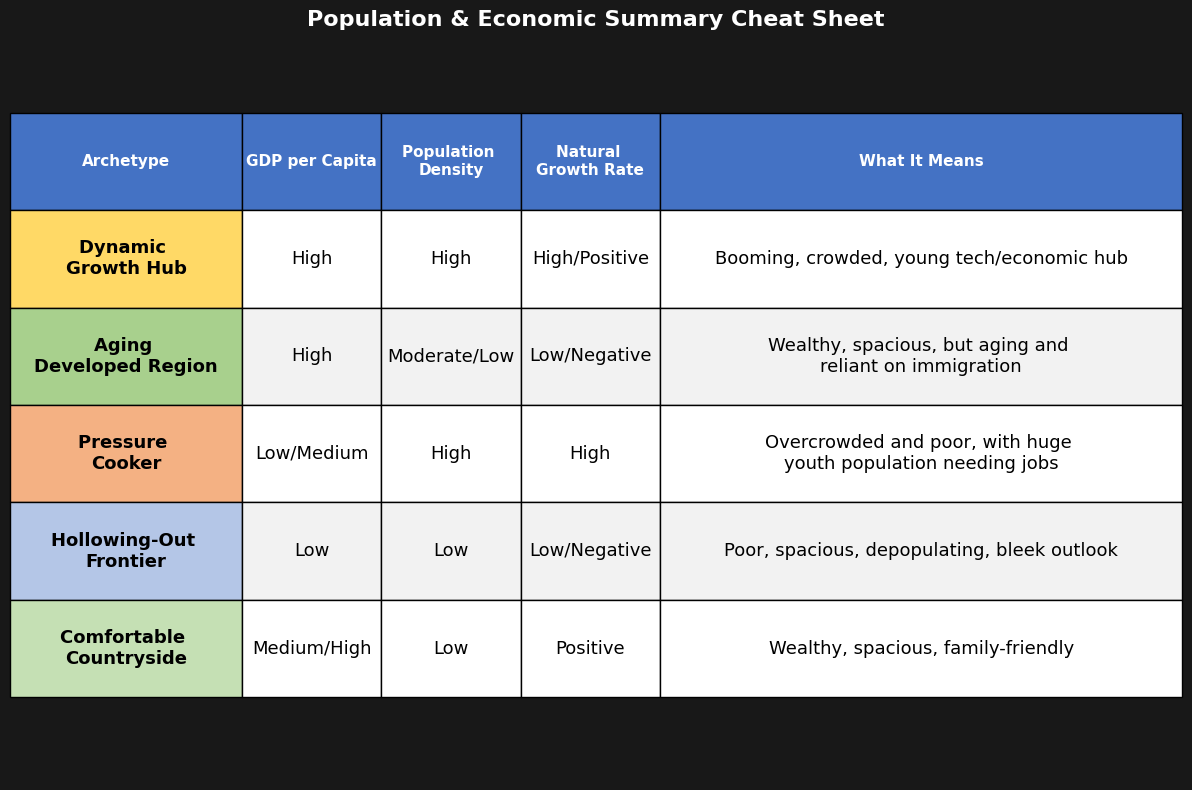

In [2]:
# table for archetypes from different combination of the three indicators
# set the style to a dark theme
plt.style.use("dark_background")

# match website background
plt.rcParams["figure.facecolor"] = "#181818"
plt.rcParams["axes.facecolor"] = "#181818"
plt.rcParams["axes.edgecolor"] = "#181818"
# Create figure and axis
fig, ax = plt.subplots(figsize=(12, 8))
ax.axis('tight')
ax.axis('off')

# Define the data
table_data = [
    ['Archetype', 'GDP per Capita', 'Population \nDensity', 'Natural \nGrowth Rate', 'What It Means'],
    ['Dynamic \nGrowth Hub', 'High', 'High', 'High/Positive', 'Booming, crowded, young tech/economic hub'],
    ['Aging \nDeveloped Region', 'High', 'Moderate/Low', 'Low/Negative', 'Wealthy, spacious, but aging and \nreliant on immigration'],
    ['Pressure \nCooker', 'Low/Medium', 'High', 'High', 'Overcrowded and poor, with huge \nyouth population needing jobs'],
    ['Hollowing-Out \nFrontier', 'Low', 'Low', 'Low/Negative', 'Poor, spacious, depopulating, bleek outlook'],
    ['Comfortable \nCountryside', 'Medium/High', 'Low', 'Positive', 'Wealthy, spacious, family-friendly']
]

# Create the table
table = ax.table(cellText=table_data, 
                 loc='center',
                 cellLoc='center',
                 colWidths=[0.2, 0.12, 0.12, 0.12, 0.45])

# Style the table
table.auto_set_font_size(False)
table.set_fontsize(13)
table.scale(1, 4.8)

# Color the header row
for i in range(5):
    table[(0, i)].set_facecolor('#4472C4')
    table[(0, i)].set_text_props(weight='bold', color='white', fontsize=11)

# Color the archetype column (first column)
archetype_colors = ['#FFD966', '#A8D08D', '#F4B183', '#B4C6E7', '#C5E0B4']
for i in range(1, 6):
    table[(i, 0)].set_facecolor(archetype_colors[i-1])
    table[(i, 0)].set_text_props(weight='bold', color='black')



# All other cells: black text
for i in range(1, 6):  # rows 1-5 (skip header)
    for j in range(1, 5):  # columns 1-4 (skip first column)
        table[(i, j)].set_text_props(color='black')
        # Add alternating row colors for better readability
        if i % 2 == 0:
            table[(i, j)].set_facecolor('#F2F2F2')
        else:
            table[(i, j)].set_facecolor('white')

# Add a title
plt.title('Population & Economic Summary Cheat Sheet', 
          fontsize=16, 
          fontweight='bold', 
          pad=-10)

# Adjust layout and display
plt.tight_layout()
plt.show()

## 4. Utility Function ##

To translate these macro indicators into a direct, quantitative comparison, we construct a utility function. This mathematical model aggregates the three distinct indicators into a single, standardized score, representing the relative investment attractiveness of each city.

$$
U = \frac{1}{\lambda P +  G + I} 
$$

Where:

+ $\lambda$: coefficient for Population and tourist density
+ $P$: Population and tourist density
+ $G$: GDP per Capita
+ $I$: Population natural increase rate


As illustrated in Figure 1, the utility score of DX (0.17) is higher than YC (0.09) and HG (0.12). This higher score is primarily driven by DX's lower population and tourist density, combined with a more negative natural growth rate.

Specifically, DX's GDP per capita is higher than YC and HG (57.3k vs. 45.7k vs. 45.1k Yuan/person, Figure 3), while its total population density (including residents and tourists) is significantly lower (129 vs. 756 vs. 472 people/km², Figure 4), and its natural growth rate is also substantially more negative (-10.6‰ vs. -5.1‰ vs. -5.8‰, Figure 7). 

These figures suggest that DX's economy is slightly more vital than its counterparts. However, when benchmarked against the national GDP per capita (95.7k Yuan/person), all three cities remain significantly below the national average, indicating a relatively weak overall economic foundation. The combination of relatively low absolute GDP per capita, extremely low population density, and a sharply negative natural growth rate places DX squarely in the "Hollowing-Out/Frontier" archetype. It is a depopulating, remote region with a weak long-term economic outlook.
Paradoxically, this severe structural decline suggests that DX may offer greater opportunities to find undervalued properties. The market has already priced in the severe population loss, creating a buyer's market where assets can be acquired at deeply discounted rates.

In contrast, YC presents a fundamentally different challenge. While it shares a similarly low GDP per capita with HG, YC’s population density is drastically inflated by an overwhelming influx of tourists (Figure 5). This combination of low local wealth and extreme crowding categorizes YC as a "Pressure Cooker." The area is physically and financially stretched to accommodate a massive, temporary population that its local economy cannot sustainably support, placing severe strain on public space and infrastructure.

Finally, HG occupies a transitional middle ground. With a GDP per capita similar to YC, its population density and natural growth rate fall between the extremes of DX and YC. Consequently, HG represents a hybrid archetype: it currently exhibits the infrastructural strain of a "Pressure Cooker," but its demographic trajectory is steadily shifting it toward a "Hollowing-Out / Frontier" status.

(Note: Please refer to Figures 3–7 in Appendix I for detailed data).

In [3]:
# calculate cost data

df['Population_Tourist_Density'] = (df['2024_Population_10k'] + 
                                    df['2024_Tourists_10k'])/df['Area_km2']
df['Population_Density'] = df['2024_Population_10k'] / df['Area_km2']
df['Tourist_Density']= df['2024_Tourists_10k'] / df['Area_km2']

df['Economy_Index'] = (df['2024_GDP_100million'] + 
                       df['2024_Tourism_Income_100_million'])/(df['2024_Population_10k'] + 
                        df['2024_Tourists_10k'])
df['GDP_per_Capita'] = df['2024_GDP_100million']/df['2024_Population_10k']

df['Cost'] = (df['Population_Tourist_Density']*100 + df['GDP_per_Capita'] 
              + df['2023_Population_Natural_Increase_Rate%']) 
df['Utility'] = 1/df['Cost']

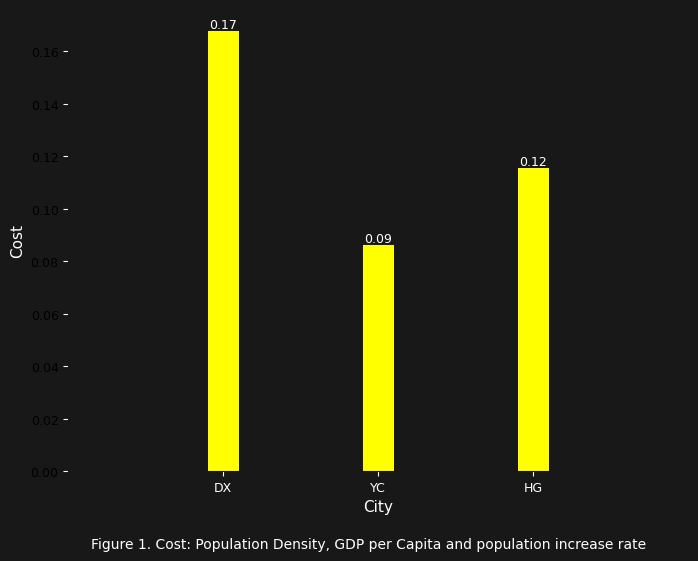

In [4]:
fig_count = 1
# set the style to a dark theme
plt.style.use("dark_background")

# match website background
plt.rcParams["figure.facecolor"] = "#181818"
plt.rcParams["axes.facecolor"] = "#181818"
plt.rcParams["axes.edgecolor"] = "#181818"
# compare population and tourist density
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar('Region', 'Utility', data= df, width=0.2, color='yellow', align='center')


ax.bar_label(bars, fontsize=9, fmt='%.2f')

plt.xticks(rotation=0, fontsize=9)
plt.yticks(fontsize=9, color='black')
plt.ylabel('Cost', fontsize=11)
plt.xlabel('City', fontsize=11)
plt.xlim([-1, 3])
plt.legend('',frameon=False)
plt.suptitle(
    f"Figure {fig_count}. Cost: Population Density, GDP per Capita and population increase rate", y=0.0001, fontsize=10
)
fig_count += 1
plt.show()


## 5. Population Loss and Property Prices ##

The relationship between population loss and real estate prices is fundamentally driven by the basic economic principle of **supply and demand**.

When a region experiences sustained population decline, the demand for housing decreases, resulting in a structural surplus of available homes. As illustrated by the red shaded area in Figure 2, this excess supply exerts immense downward pressure on property values.

Beyond the immediate price drop, population loss triggers a cascading negative cycle. The local market transforms into a closed loop where existing residents merely trade properties among themselves, with no new external capital entering the system. This leads to rising vacancy rates and, eventually, urban decay. As neighborhoods empty out, properties suffer from reduced maintenance, and local governments face shrinking tax revenues. Consequently, public investment in essential services, such as education, healthcare, and infrastructure, declines. This degradation further depresses property values, creating a self-reinforcing downward spiral for the real estate market.

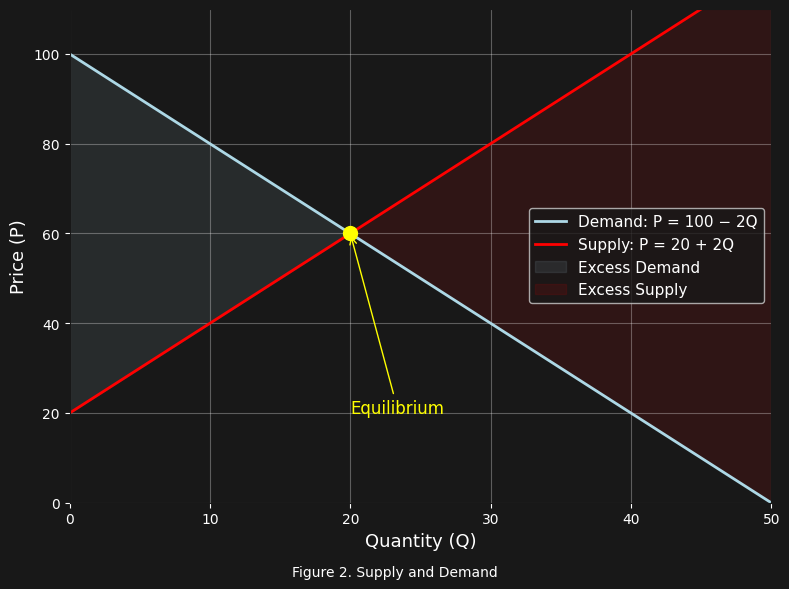

In [5]:
# Demand: P = 100 - 2Q
# Supply: P = 20 + 2Q
Q = np.linspace(0, 50, 100)
demand = 100 - 2 * Q
supply = 20 + 2 * Q

# Equilibrium: 100 - 2Q = 20 + 2Q → Q* = 20, P* = 60
Q_eq = 20
P_eq = 60

plt.figure(figsize=(8, 6))
plt.plot(Q, demand, color='lightblue', linewidth=2, label='Demand: P = 100 − 2Q')
plt.plot(Q, supply, 'r-', linewidth=2, label='Supply: P = 20 + 2Q')

plt.scatter(Q_eq, P_eq, color='yellow', s=100, zorder=5)
plt.annotate(f'Equilibrium',
             xy=(Q_eq, P_eq), xytext=(20, 20),
             arrowprops=dict(arrowstyle='->', color='yellow'),
             fontsize=12, color='yellow')

# Shade surplus & shortage regions
plt.fill_between(Q, demand, supply, where=(demand > supply), 
                 alpha=0.1, color='lightblue', label='Excess Demand')
plt.fill_between(Q, demand, supply, where=(supply > demand), 
                 alpha=0.1, color='red', label='Excess Supply')

plt.xlabel('Quantity (Q)', fontsize=13)
plt.ylabel('Price (P)', fontsize=13)
plt.suptitle(
    f"Figure {fig_count}. Supply and Demand", y=0.0001, fontsize=10
)
plt.legend(fontsize=11)
plt.xlim(0, 50)
plt.ylim(0, 110)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
fig_count += 1

## 6. Conclusion ##

This research establishes that macro analysis is a vital tool for holistically assessing the fundamental **competitiveness** of a region. By synthesizing metrics like GDP per capita with demographic trends, we move beyond superficial valuations to reveal the structural reality of a region. By classifying regions into distinct archetypes. It allows us to predict how demographic shifts will interact with housing supply. Competitiveness is not static; it is dynamically linked to population flows. A region that cannot retain or attract human capital will eventually see its real estate market decouple from broader economic trends, trapped in a cycle of surplus supply and diminishing demand.

Moving forward, we will procceed with micro analysis on particular assets, or neighborhood. 

## Appendix I ##

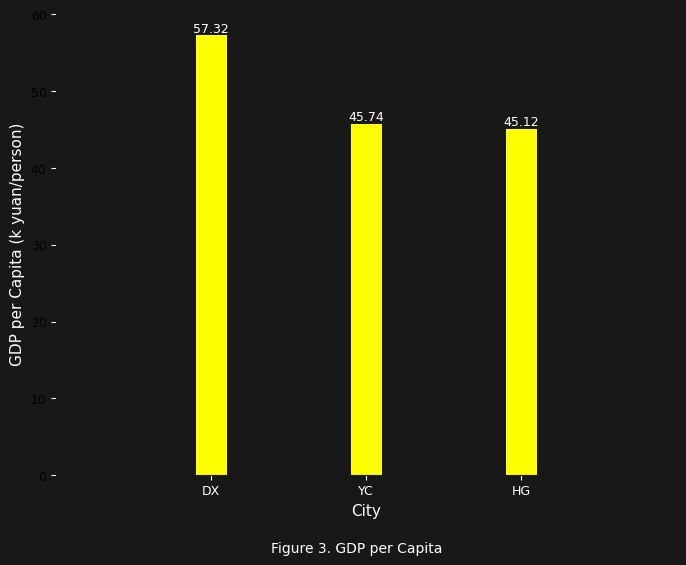

In [6]:
# compare population and tourist density
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(df['Region'], df['GDP_per_Capita']*10, data= df, width=0.2, color='yellow', align='center')


ax.bar_label(bars, fontsize=9, fmt='%.2f')

plt.xticks(rotation=0, fontsize=9)
plt.yticks(fontsize=9, color='black')
plt.ylabel('GDP per Capita (k yuan/person)', fontsize=11)
plt.xlabel('City', fontsize=11)
plt.xlim([-1, 3])
plt.legend('',frameon=False)
plt.suptitle(
    f"Figure {fig_count}. GDP per Capita", y=0.0001, fontsize=10
)
fig_count += 1
plt.show()

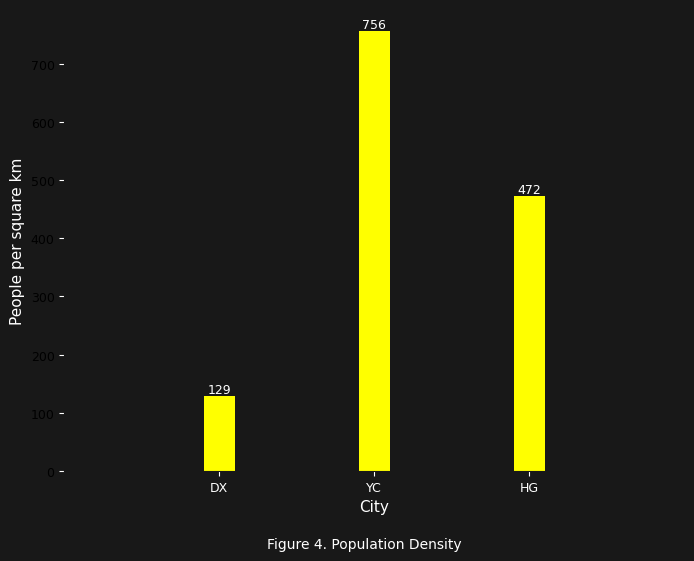

In [7]:
# compare population and tourist density
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(df['Region'], df['Population_Tourist_Density']*10000, width=0.2, color='yellow', align='center')


ax.bar_label(bars, fontsize=9, fmt='%.0f')

plt.xticks(rotation=0, fontsize=9)
plt.yticks(fontsize=9, color='black')
plt.ylabel('People per square km', fontsize=11)
plt.xlabel('City', fontsize=11)
plt.xlim([-1, 3])
plt.legend('',frameon=False)
plt.suptitle(
    f"Figure {fig_count}. Population Density", y=0.0001, fontsize=10
)
fig_count += 1
plt.show()


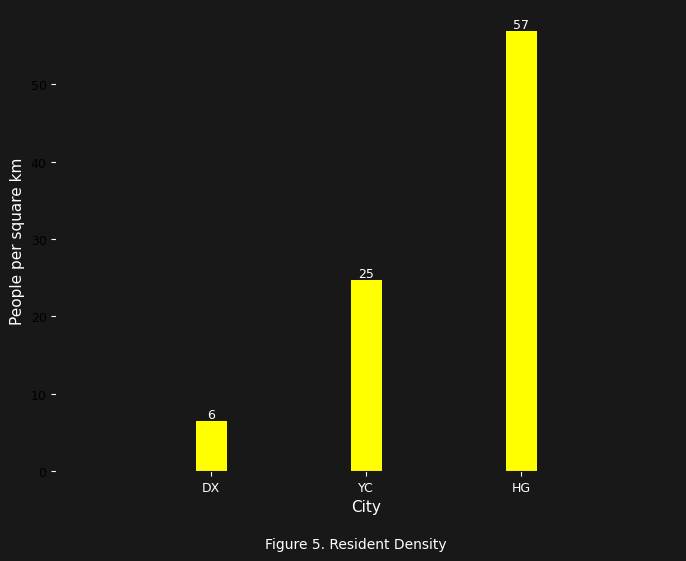

In [8]:
# compare population and tourist density
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(df['Region'], df['Population_Density']*10000, width=0.2, color='yellow', align='center')


ax.bar_label(bars, fontsize=9, fmt='%.0f')

plt.xticks(rotation=0, fontsize=9)
plt.yticks(fontsize=9, color='black')
plt.ylabel('People per square km', fontsize=11)
plt.xlabel('City', fontsize=11)
plt.xlim([-1, 3])
plt.legend('',frameon=False)
plt.suptitle(
    f"Figure {fig_count}. Resident Density", y=0.0001, fontsize=10
)
fig_count += 1
plt.show()


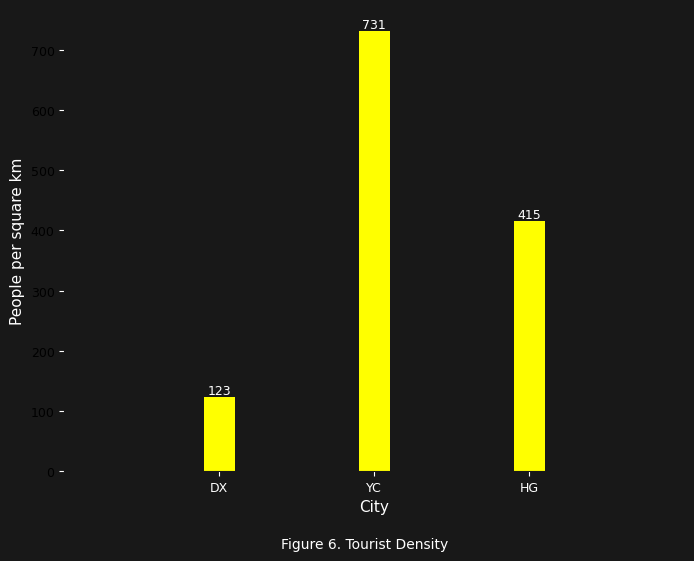

In [9]:
# compare population and tourist density
fig, ax = plt.subplots(figsize=(8, 6))

bars = ax.bar(df['Region'], df['Tourist_Density'] * 10000, width=0.2, color='yellow', align='center')

# Add labels with the rounded multiplied values
ax.bar_label(bars, fontsize=9, fmt='%.0f')  # '%.0f' ensures integer display

plt.xticks(rotation=0, fontsize=9)
plt.yticks(fontsize=9, color='black')
plt.ylabel('People per square km', fontsize=11)
plt.xlabel('City', fontsize=11)
plt.xlim([-1, 3])
plt.legend('',frameon=False)
plt.suptitle(
    f"Figure {fig_count}. Tourist Density", y=0.0001, fontsize=10
)
fig_count += 1
plt.show()


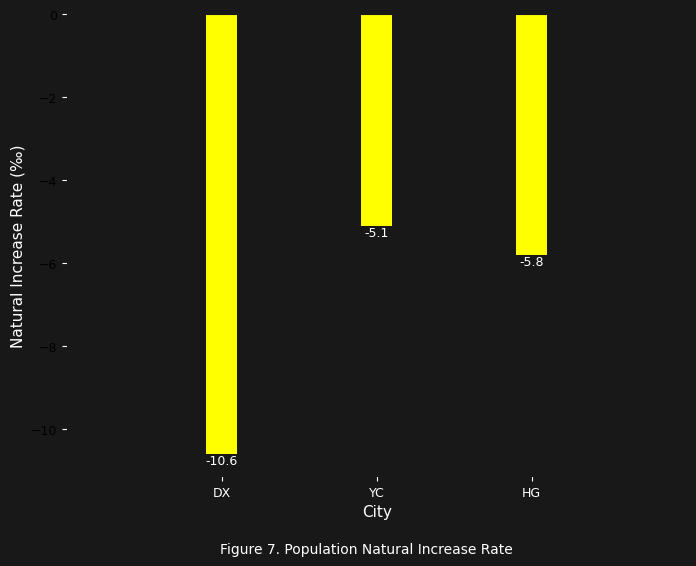

In [10]:
# compare population and tourist density
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(df['Region'], df['2023_Population_Natural_Increase_Rate%']*10, data= df, width=0.2, color='yellow', align='center')


ax.bar_label(bars, fontsize=9)

plt.xticks(rotation=0, fontsize=9)
plt.yticks(fontsize=9, color='black')
plt.ylabel('Natural Increase Rate (‰)', fontsize=11)
plt.xlabel('City', fontsize=11)
plt.xlim([-1, 3])
plt.legend('',frameon=False)
plt.suptitle(
    f"Figure {fig_count}. Population Natural Increase Rate", y=0.0001, fontsize=10
)
fig_count += 1
plt.show()
